In [1]:
import pandas as pd

df=pd.read_excel("C:\\Users\\ABHINAV AR\\Data.xlsx")
df

,transaction_id,sender_account,receiver_account,sender_country,receiver_country,transaction_amount,currency,transaction_type,transaction_date,transaction_frequency_7d,cash_transaction,offshore_account,politically_exposed_person,shell_company,sanctions_match,customer_risk_score,suspicious_flag
0,AML00001,SA100002,RA200002,MY,IN,20272,MYR,Online Transfer,2026-07-01,7,Yes,No,No,No,No,14,0
1,AML00002,SA100003,RA200003,MY,SG,67010,USD,Wire Transfer,2026-07-02,4,Yes,No,No,No,No,15,0
2,AML00003,SA100004,RA200004,MY,IN,72726,MYR,Cash Deposit,2026-07-03,7,Yes,No,No,No,No,62,0
3,AML00004,SA100005,RA200005,MY,MY,76914,MYR,RTGS,2026-07-04,1,No,No,No,No,No,13,0
4,AML00005,SA100006,RA200006,MY,MY,38459,SGD,Online Transfer,2026-07-05,7,Yes,No,No,No,No,44,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,AML00096,SA100097,RA200097,MY,SG,47704,MYR,SWIFT,2026-07-06,3,Yes,No,No,No,No,15,0
96,AML00097,SA100098,RA200098,MY,MY,58939,MYR,Wire Transfer,2026-07-07,7,No,No,No,No,No,64,0
97,AML00098,SA100099,RA200099,MY,MY,62532,USD,RTGS,2026-07-08,10,No,No,No,No,No,10,0
98,AML00099,SA100100,RA200100,MY,MY,59344,MYR,RTGS,2026-07-09,4,Yes,No,No,No,No,24,0


In [2]:
df.head()
print(df.shape)
df.info()

(100, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   transaction_id              100 non-null    object
 1   sender_account              100 non-null    object
 2   receiver_account            100 non-null    object
 3   sender_country              100 non-null    object
 4   receiver_country            100 non-null    object
 5   transaction_amount          100 non-null    int64 
 6   currency                    100 non-null    object
 7   transaction_type            100 non-null    object
 8   transaction_date            100 non-null    object
 9   transaction_frequency_7d    100 non-null    int64 
 10  cash_transaction            100 non-null    object
 11  offshore_account            100 non-null    object
 12  politically_exposed_person  100 non-null    object
 13  shell_company               100 non-null 

In [3]:
df['transaction_date'] = pd.to_datetime(df['transaction_date'],errors='coerce')
df.isnull().sum()
df.duplicated().sum()

0

In [4]:
df = df.drop(columns=[
    "transaction_id",
    "sender_account",
    "receiver_account",
    "sender_country",
    "transaction_date"
])

# Convert categorical columns into numerical columns
df = pd.get_dummies(df, drop_first=True)

# Separate input and target
X = df.drop("suspicious_flag", axis=1)
y = df["suspicious_flag"]

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [8]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00         4

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



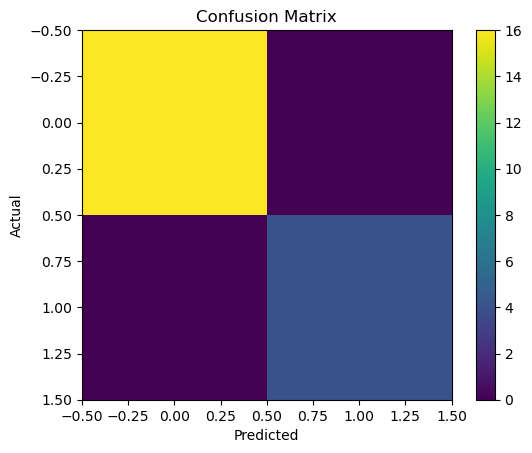

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

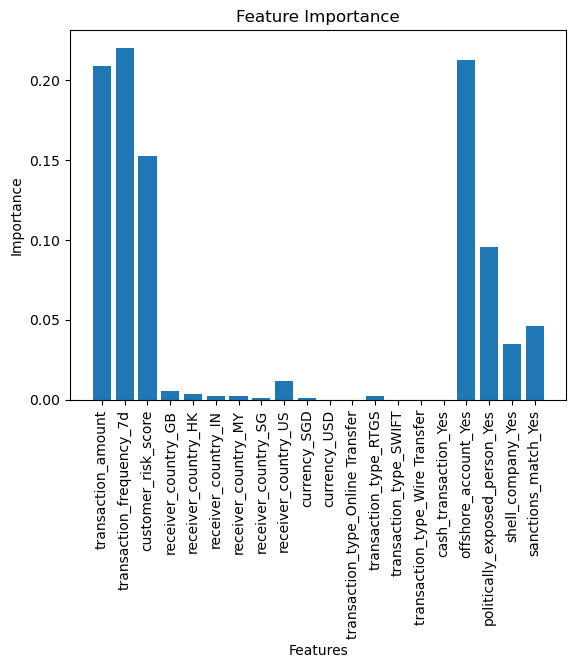

In [10]:
plt.bar(X_train.columns, model.feature_importances_)

plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=90)
plt.show()

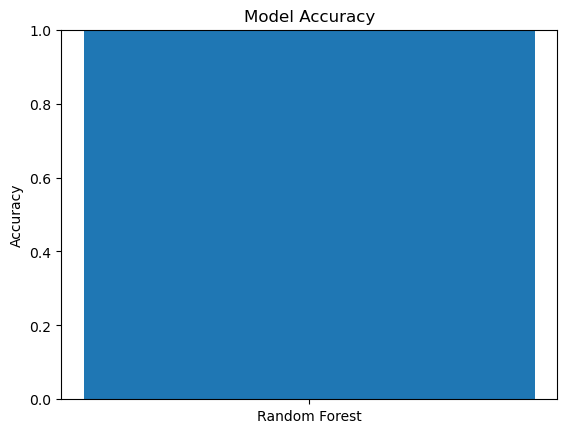

Accuracy: 1.0


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

plt.bar(["Random Forest"], [accuracy])
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

print("Accuracy:", accuracy)